In [1]:
import os
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time
import torchvision.models as models
from matplotlib import pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit
from torch.utils.data import random_split

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')   # Apple Silicon GPU
else:
    device = torch.device('cpu')
device

device(type='mps')

## Load the Dataset

In [3]:
image_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [4]:
dataset_path = "./dataset"
dataset = datasets.ImageFolder(dataset_path, transform=image_transform)
len(dataset)

2300

In [5]:
dataset.classes

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [6]:
num_classes = len(dataset.classes)
num_classes

6

In [7]:
train_size = int(0.75*len(dataset))
val_size = len(dataset) - train_size
train_size, val_size

(1725, 575)

In [8]:
class_name = dataset.classes
class_name

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

### Splitting the data into train and test dataset

In [9]:
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

### Loading the data using data loader

In [10]:
NUM_WORKERS = min(4, os.cpu_count() or 1)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=NUM_WORKERS, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=NUM_WORKERS, persistent_workers=True)

In [11]:
for images, labels in train_loader:
    print(images.shape, labels.shape)
    break

torch.Size([32, 3, 224, 224]) torch.Size([32])


### 32 is batch size 3 is color chanel i.e rgb 256, 256 is width and length

In [12]:
images[0].shape

torch.Size([3, 224, 224])

In [13]:
labels[0]

tensor(5)

In [14]:
images[0].permute(1,2,0).shape

torch.Size([224, 224, 3])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.622571].


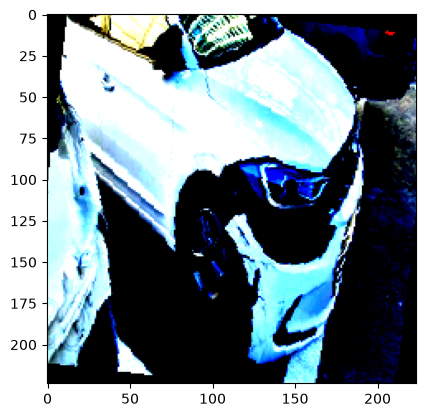

In [15]:
plt.imshow(images[1].permute(1,2,0))
plt.show()

### Train the Model using CNN

In [16]:
class CarClassifierCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # in: (3,224,224) out: (16,224,224)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),  # out: (16, 112, 112)
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), # in: (16,112,112) out: (32,112,112)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),  # out: (32, 56, 56)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), # in: (32,56,56) out: (64,56,56)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),  # out: (64, 28, 28)
            nn.Flatten(),
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes),
        )
    def forward(self, x):
        x = self.network(x)
        return x

In [17]:
model = CarClassifierCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [18]:
images.size(0), len(train_loader.dataset)

(32, 1725)

In [19]:
def train_model(model, criterion, optimizer, epochs=5):
    start = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        # Mini batch
        for batch_num, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            if (batch_num + 1) % 10 == 0:
                print(f"Batch: {batch_num + 1}, Epoch: {epoch+1} ,Loss: {loss.item():.2f}")
            running_loss += loss.item() * images.size(0)
        epoch_loss = running_loss/len(train_loader.dataset)
        print(f"Epoch [{epoch+1}/{epochs}], Avg Loss: {epoch_loss:.4f}")

        # Validation
        model.eval()
        correct = 0
        total = 0
        all_labels = []
        all_predictions = []
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())
            print(f"*** Validation Accuracy: {100 * correct / total:.2f}% ***")
    end = time.time()
    print(f"Execution Time: {end-start} seconds")
    return all_labels, all_predictions

In [20]:
values, indeices = torch.max(torch.tensor([[10,12,15,9,2]]), 1)
values, indeices

(tensor([15]), tensor([2]))

In [21]:
all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=6)

Batch: 10, Epoch: 1 ,Loss: 1.78


Batch: 20, Epoch: 1 ,Loss: 1.75


Batch: 30, Epoch: 1 ,Loss: 1.73


Batch: 40, Epoch: 1 ,Loss: 1.58


Batch: 50, Epoch: 1 ,Loss: 1.64


Epoch [1/6], Avg Loss: 1.8158


... (32 outputs left out)

Batch: 40, Epoch: 6 ,Loss: 1.28


Batch: 50, Epoch: 6 ,Loss: 1.31


Epoch [6/6], Avg Loss: 1.1707


*** Validation Accuracy: 48.70% ***
Execution Time: 38.619900941848755 seconds


# CNN with Regularization

In [22]:
class CarClassifierCNNWithregularization(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # in: (3,224,224) out: (16,224,224)
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),  # out: (16, 112, 112)
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), # in: (16,112,112) out: (32,112,112)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),  # out: (32, 56, 56)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), # in: (32,56,56) out: (64,56,56)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0),  # out: (64, 28, 28)
            nn.Flatten(),
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes),
        )
    def forward(self, x):
        x = self.network(x)
        return x

In [23]:
model = CarClassifierCNNWithregularization(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

In [24]:
all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=5)

Batch: 10, Epoch: 1 ,Loss: 22.34


Batch: 20, Epoch: 1 ,Loss: 6.82


Batch: 30, Epoch: 1 ,Loss: 3.12


Batch: 40, Epoch: 1 ,Loss: 1.93


Batch: 50, Epoch: 1 ,Loss: 1.47


Epoch [1/5], Avg Loss: 8.4459


... (25 outputs left out)

Batch: 40, Epoch: 5 ,Loss: 1.11


Batch: 50, Epoch: 5 ,Loss: 1.10


Epoch [5/5], Avg Loss: 1.2144


*** Validation Accuracy: 46.61% ***
Execution Time: 35.471235275268555 seconds


### Transfer Learning with EfficientNet

In [25]:
model = models.efficientnet_b0(weights='DEFAULT')
model.classifier[1].in_features

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /Users/sunny/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


  0%|          | 0.00/20.5M [00:00<?, ?B/s]

  2%|▏         | 512k/20.5M [00:00<00:04, 5.07MB/s]

  7%|▋         | 1.38M/20.5M [00:00<00:02, 7.40MB/s]

 10%|█         | 2.12M/20.5M [00:00<00:03, 5.19MB/s]

 14%|█▍        | 2.88M/20.5M [00:00<00:03, 5.14MB/s]

... (31 outputs left out)

 97%|█████████▋| 19.9M/20.5M [00:06<00:00, 2.11MB/s]

 98%|█████████▊| 20.1M/20.5M [00:06<00:00, 2.04MB/s]

100%|██████████| 20.5M/20.5M [00:06<00:00, 3.30MB/s]

1280

In [26]:
class CarClassifierCNNWfficientNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.efficientnet_b0(weights='DEFAULT')
        # Freezing the other layers
        for param in self.model.parameters():
            param.requires_grad = False
        in_features = self.model.classifier[1].in_features
        # this is the last layer for classification
        self.model.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, num_classes),
        )
    def forward(self,x):
        x = self.model(x)
        return x

In [27]:
model = CarClassifierCNNWfficientNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

In [28]:
train_model(model, criterion, optimizer, epochs=5)

Batch: 10, Epoch: 1 ,Loss: 1.69


Batch: 20, Epoch: 1 ,Loss: 1.56


Batch: 30, Epoch: 1 ,Loss: 1.48


Batch: 40, Epoch: 1 ,Loss: 1.39


Batch: 50, Epoch: 1 ,Loss: 1.29


Epoch [1/5], Avg Loss: 1.4985


... (26 outputs left out)

Batch: 50, Epoch: 5 ,Loss: 1.14


Epoch [5/5], Avg Loss: 0.9877


*** Validation Accuracy: 60.70% ***
Execution Time: 54.98352265357971 seconds


([np.int64(3),
  np.int64(1),
  np.int64(5),
  np.int64(1),
  np.int64(5),
  np.int64(2),
  np.int64(4),
  np.int64(3),
  np.int64(4),
  np.int64(0),
  np.int64(0),
  np.int64(2),
  np.int64(0),
  np.int64(0),
  np.int64(3),
  np.int64(3),
  np.int64(5),
  np.int64(0),
  np.int64(4),
  np.int64(2),
  np.int64(0),
  np.int64(0),
  np.int64(2),
  np.int64(4),
  np.int64(1),
  np.int64(4),
  np.int64(3),
  np.int64(0),
  np.int64(1),
  np.int64(5),
  np.int64(2),
  np.int64(3),
  np.int64(5),
  np.int64(0),
  np.int64(1),
  np.int64(1),
  np.int64(1),
  np.int64(1),
  np.int64(3),
  np.int64(5),
  np.int64(2),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(5),
  np.int64(1),
  np.int64(5),
  np.int64(4),
  np.int64(5),
  np.int64(5),
  np.int64(0),
  np.int64(1),
  np.int64(2),
  np.int64(0),
  np.int64(4),
  np.int64(0),
  np.int64(3),
  np.int64(5),
  np.int64(3),
  np.int64(0),
  np.int64(4),
  np.int64(3),
  np.int64(4),
  np.int64(4),
  np.int64(4),
  np.int64(5),
  np.int64

### Transfer Learning Using resNet

In [29]:
class CarClassifierCNNResNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.resnet50(weights='DEFAULT')
        # Freezing all the layer except the final fully connected layer
        for param in self.model.parameters():
            param.requires_grad = False
        # Unfreze layer4 and fc layesr
        for param in self.model.layer4.parameters():
            param.requires_grad = True
        # this is the last layer for fully connected layer i.e fc
        self.model.fc = nn.Sequential(
            nn.Dropout(0.3942947142510578),
            nn.Linear(self.model.fc.in_features, num_classes),
        )
    def forward(self,x):
        x = self.model(x)
        return x

In [30]:
model = CarClassifierCNNResNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.000871743346606561)
labels, predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1 ,Loss: 1.17


Batch: 20, Epoch: 1 ,Loss: 0.87


Batch: 30, Epoch: 1 ,Loss: 0.64


Batch: 40, Epoch: 1 ,Loss: 0.81


Batch: 50, Epoch: 1 ,Loss: 0.71


Epoch [1/10], Avg Loss: 0.9526


... (60 outputs left out)

Batch: 40, Epoch: 10 ,Loss: 0.24


Batch: 50, Epoch: 10 ,Loss: 0.10


Epoch [10/10], Avg Loss: 0.1639


*** Validation Accuracy: 73.91% ***
Execution Time: 275.00408697128296 seconds


## Model evaluation using confusion matrix and classification report

In [31]:
print(labels[:10])
print(predictions[:10])

[np.int64(3), np.int64(1), np.int64(5), np.int64(1), np.int64(5), np.int64(2), np.int64(4), np.int64(3), np.int64(4), np.int64(0)]
[np.int64(3), np.int64(1), np.int64(5), np.int64(1), np.int64(5), np.int64(2), np.int64(3), np.int64(3), np.int64(5), np.int64(0)]


In [32]:
from sklearn.metrics import classification_report
report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.74      0.89      0.81       104
           1       0.77      0.49      0.60        94
           2       0.79      0.91      0.85       129
           3       0.75      0.69      0.72        77
           4       0.68      0.56      0.61        90
           5       0.68      0.80      0.73        81

    accuracy                           0.74       575
   macro avg       0.73      0.72      0.72       575
weighted avg       0.74      0.74      0.73       575



## Transfer Learning Using YOLOv8 (Classification)

### Why YOLOv8?
ResNet gave us ~50% accuracy. YOLOv8 (via `ultralytics`) is a modern, highly optimised backbone
that supports image **classification** out of the box with a simple API and faster convergence.

### Step 1 – Install ultralytics (if not already installed)

In [33]:
# Run only once – skip if ultralytics is already in the venv
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'ultralytics', '-q'], check=True)
print('ultralytics available')

ultralytics available


### Step 2 – Prepare the Dataset Structure for YOLOv8
YOLOv8 classification expects:
```
yolo_dataset/
  train/ { crack/, dent/, glass_shatter/, lamp_broken/, scratch/, tire_flat/ }
  val/   { crack/, dent/, glass_shatter/, lamp_broken/, scratch/, tire_flat/ }
```
We build this from `./dataset` using the same 75/25 split used earlier.

In [34]:
import os
import shutil
import random

SOURCE_DIR  = './dataset'
TARGET_DIR  = './yolo_dataset'
TRAIN_RATIO = 0.75
SEED        = 42

random.seed(SEED)

CLASSES = sorted(
    c for c in os.listdir(SOURCE_DIR)
    if not c.startswith('.') and os.path.isdir(os.path.join(SOURCE_DIR, c))
)

# Remove previous build if it exists
if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

for split in ('train', 'val'):
    for cls in CLASSES:
        os.makedirs(os.path.join(TARGET_DIR, split, cls), exist_ok=True)

for cls in CLASSES:
    cls_path = os.path.join(SOURCE_DIR, cls)
    images = [
        f for f in os.listdir(cls_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]
    random.shuffle(images)
    split_idx = int(len(images) * TRAIN_RATIO)
    for fname in images[:split_idx]:
        shutil.copy(
            os.path.join(cls_path, fname),
            os.path.join(TARGET_DIR, 'train', cls, fname)
        )
    for fname in images[split_idx:]:
        shutil.copy(
            os.path.join(cls_path, fname),
            os.path.join(TARGET_DIR, 'val', cls, fname)
        )

# Sanity check
for split in ('train', 'val'):
    total = sum(
        len(os.listdir(os.path.join(TARGET_DIR, split, c)))
        for c in os.listdir(os.path.join(TARGET_DIR, split))
    )
    print(f'{split}: {total} images')

train: 1725 images
val: 575 images


### Step 3 – Load the YOLOv8 Classification Model
`yolov8n-cls.pt` is the **nano** (fastest) variant pretrained on ImageNet.
For higher accuracy try `yolov8s-cls.pt` or `yolov8m-cls.pt`.

In [35]:
from ultralytics import YOLO

# Load pretrained YOLOv8 nano classification model
yolo_model = YOLO('yolov8n-cls.pt')
print('Model loaded:', type(yolo_model))

Model loaded: <class 'ultralytics.models.yolo.model.YOLO'>


### Step 4 – Train the YOLOv8 Model

In [36]:
results = yolo_model.train(
    data     = TARGET_DIR,   # path to yolo_dataset/
    epochs   = 10,
    imgsz    = 224,           # same image size used in rest of notebook
    batch    = 32,
    device   = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'),
    workers  = 4,
    project  = 'yolo_runs',
    name     = 'car_damage_cls',
    exist_ok = True,
    verbose  = True
)
print('Training complete!')
print('Best model saved at:', results.save_dir)

Ultralytics 8.4.189 🚀 Python-3.12.13 torch-2.14.1 MPS (Apple M4)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./yolo_dataset, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=car_damage_cls, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pr

train: /Users/sunny/Apsit/Car-Detection/damage-prediction/training/yolo_dataset/train... found 1725 images in 6 classes ✅ 


val: /Users/sunny/Apsit/Car-Detection/damage-prediction/training/yolo_dataset/val... found 575 images in 6 classes ✅ 


test: None...


Overriding model.yaml nc=1000 with nc=6


... (704 outputs left out)

                   all      0.803          1


Speed: 0.0ms preprocess, 0.9ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to /Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls


Training complete!
Best model saved at: /Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls


### Step 5 – Evaluate on the Validation Set

In [37]:
import os
import torch
import numpy as np

# Use the in-memory trained model if available, otherwise load from disk
try:
    _eval_model = yolo_model   # already trained in Step 4
    print('Using in-memory trained model.')
except NameError:
    from ultralytics import YOLO
    # Try to find best.pt from results, then fall back to a fixed path
    try:
        best_weights = os.path.join(str(results.save_dir), 'weights', 'best.pt')
    except NameError:
        best_weights = os.path.join('yolo_runs', 'car_damage_cls', 'weights', 'best.pt')
    _eval_model = YOLO(best_weights)
    print('Loaded model from:', best_weights)

# Class names in sorted order (same as ImageFolder)
val_dir    = os.path.join(TARGET_DIR, 'val')
cls_names  = sorted(
    c for c in os.listdir(val_dir)
    if not c.startswith('.') and os.path.isdir(os.path.join(val_dir, c))
)
cls_to_idx = {c: i for i, c in enumerate(cls_names)}

yolo_all_labels      = []
yolo_all_predictions = []

for cls in cls_names:
    cls_val_path = os.path.join(val_dir, cls)
    for fname in os.listdir(cls_val_path):
        fpath = os.path.join(cls_val_path, fname)
        try:
            pred = _eval_model.predict(fpath, verbose=False)[0]
            yolo_all_labels.append(cls_to_idx[cls])
            yolo_all_predictions.append(int(pred.probs.top1))
        except Exception as e:
            print(f'[SKIPPED] {fpath}: {e}')

accuracy = np.mean(np.array(yolo_all_labels) == np.array(yolo_all_predictions))
print(f'\n*** YOLOv8 Validation Accuracy: {accuracy * 100:.2f}% ***\n')

Using in-memory trained model.



*** YOLOv8 Validation Accuracy: 80.35% ***



### Step 6 – Classification Report

In [38]:
from sklearn.metrics import classification_report

report = classification_report(yolo_all_labels, yolo_all_predictions, target_names=cls_names)
print(report)

              precision    recall  f1-score   support

  F_Breakage       0.88      0.90      0.89       125
   F_Crushed       0.76      0.84      0.80       100
    F_Normal       0.92      0.83      0.87       125
  R_Breakage       0.80      0.81      0.81        75
   R_Crushed       0.63      0.68      0.65        75
    R_Normal       0.73      0.65      0.69        75

    accuracy                           0.80       575
   macro avg       0.79      0.79      0.79       575
weighted avg       0.81      0.80      0.80       575



### Step 7 – Confusion Matrix

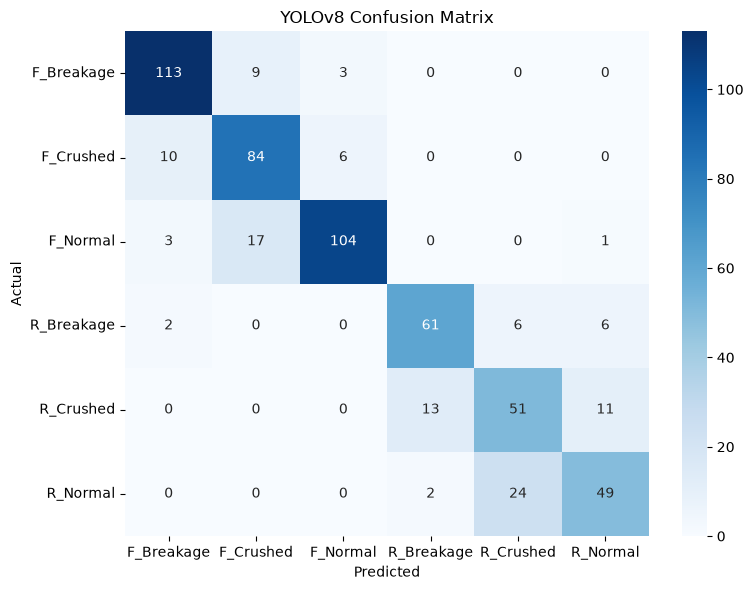

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(yolo_all_labels, yolo_all_predictions)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=cls_names, yticklabels=cls_names
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('YOLOv8 Confusion Matrix')
plt.tight_layout()
plt.show()

### Step 8 – Export / Save the Final Model
Export to **ONNX** for inference in production, or keep `.pt` weights for Torch-based serving.

In [40]:
# Export to ONNX (optional – comment out if not needed)
# _eval_model was set in the evaluation cell above
_eval_model.export(format='onnx', imgsz=224)
print('Model exported to ONNX format.')

# Show where the best PyTorch weights are saved
import os
try:
    _best_pt = os.path.join(str(results.save_dir), 'weights', 'best.pt')
except NameError:
    _best_pt = os.path.join('yolo_runs', 'car_damage_cls', 'weights', 'best.pt')
print('PyTorch best weights:', _best_pt)

Ultralytics 8.4.189 🚀 Python-3.12.13 torch-2.14.1 CPU (Apple M4)


YOLOv8n-cls summary (fused): 30 layers, 1,442,566 parameters, 0 gradients, 0.4 GFLOPs



PyTorch: starting from '/Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls/weights/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 6) (2.8 MB)



ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: slimming with onnxslim 0.1.98...


ONNX: export success ✅ 3.5s, saved as '/Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls/weights/best.onnx' (5.5 MB)



Export complete (3.6s)
Results saved to /Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls/weights/best.onnx
Predict:         yolo predict task=classify model=/Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls/weights/best.onnx imgsz=224 
Validate:        yolo val task=classify model=/Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls/weights/best.onnx imgsz=224 data=./yolo_dataset 
Visualize:       https://netron.app


Model exported to ONNX format.
PyTorch best weights: /Users/sunny/Apsit/Car-Detection/runs/classify/yolo_runs/car_damage_cls/weights/best.pt
